# Linear regression in diabetes dataset

Let's explore the datasets that are included in this Python library. These datasets have been cleaned and formatted for use in ML algorithms.

First, we will load the diabetes dataset. Do this in the cell below by importing the datasets and then loading the dataset  to the `diabetes` variable using the `load_diabetes()` function ([documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)).

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

In [11]:
import pandas as pd
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()

In [12]:
diabetes

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]]),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142., 155., 225.,  59

Let's explore this variable by looking at the different attributes (keys) of `diabetes`. Note that the `load_diabetes` function does not return dataframes. It returns you a Python dictionary.

In [13]:
diabetes.keys()

dict_keys(['data', 'target', 'frame', 'DESCR', 'feature_names', 'data_filename', 'target_filename', 'data_module'])

#### The next step is to read the description of the dataset. 

Print the description in the cell below using the `DESCR` attribute of the `diabetes` variable. Read the data description carefully to fully understand what each column represents.

*Hint: If your output is ill-formatted by displaying linebreaks as `\n`, it means you are not using the `print` function.*

In [14]:
print(diabetes['DESCR'])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

  :Number of Instances: 442

  :Number of Attributes: First 10 columns are numeric predictive values

  :Target: Column 11 is a quantitative measure of disease progression one year after baseline

  :Attribute Information:
      - age     age in years
      - sex
      - bmi     body mass index
      - bp      average blood pressure
      - s1      tc, total serum cholesterol
      - s2      ldl, low-density lipoproteins
      - s3      hdl, high-density lipoproteins
      - s4      tch, total cholesterol / HDL
      - s5      ltg, possibly log of serum triglycerides level
      - s6      glu, blood sugar level

Note: Each of these 1

#### Based on the data description, answer the following questions:

1. How many attributes are there in the data? What do they mean?

1. What is the relation between `diabetes['data']` and `diabetes['target']`?

1. How many records are there in the data?

In [15]:
import pandas as pd

In [16]:
df_data = pd.DataFrame(diabetes['data'], columns=diabetes['feature_names'])
df_data

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [17]:
# 1. 
print('Nº de atributos en los datos:', len(diabetes['feature_names']))
print("Significado de los datos: ver :Attribute Information en diabetes['DESCR']")
print()

# 2. 
print("diabetes['target'] tiene las observaciones para los registros de diabetes['data'] (diabetes['data'] ~ X; diabetes['target'] ~ y).")
print()

# 3. 
print(f"Nº de registros en los datos: {len(diabetes['target'])}")


Nº de atributos en los datos: 10
Significado de los datos: ver :Attribute Information en diabetes['DESCR']

diabetes['target'] tiene las observaciones para los registros de diabetes['data'] (diabetes['data'] ~ X; diabetes['target'] ~ y).

Nº de registros en los datos: 442


#### Now explore what are contained in the *data* portion as well as the *target* portion of `diabetes`. 

Scikit-learn typically takes in 2D numpy arrays as input (though pandas dataframes are also accepted). Inspect the shape of `data` and `target`. Confirm they are consistent with the data description.

In [18]:
print(diabetes['data'].shape)
print(diabetes['target'].shape)

(442, 10)
(442,)


## Building a regression model

The data have already been split to predictor (*data*) and response (*target*) variables. Given this information, we'll apply what we have previously learned about linear regression and apply the algorithm to the diabetes dataset.

#### In the cell below, import the `linear_model` class from `sklearn`. 

In [19]:
from sklearn import linear_model

#### Create a new instance of the linear regression model and assign the new instance to the variable `diabetes_model`.

In [20]:
diabetes_model = linear_model.LinearRegression()

#### Next, let's split the training and test data.

Define `diabetes_data_train`, `diabetes_target_train`, `diabetes_data_test`, and `diabetes_target_test`. Use the last 20 records for the test data and the rest for the training data.

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
# X_train, X_test, y_train, y_test = train_test_split(diabetes['data'], diabetes['target'], test_size = 0.20, random_state = 42)
diabetes_data_train = diabetes['data'][:-20]
diabetes_data_test = diabetes['data'][-20:]
diabetes_target_train = diabetes['target'][:-20]
diabetes_target_test = diabetes['target'][-20:]

Perform a brief exploratory analysis to investigate the conditions necessary for linear regression. This analysis will help you understand the distribution of the target variable and its correlations with other features.

In [23]:
import seaborn as sns

In [24]:
df_diabetes = pd.DataFrame(diabetes['data'], columns=diabetes['feature_names'])
df_diabetes['disease progr'] = diabetes['target']
df_diabetes

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,disease progr
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0


c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


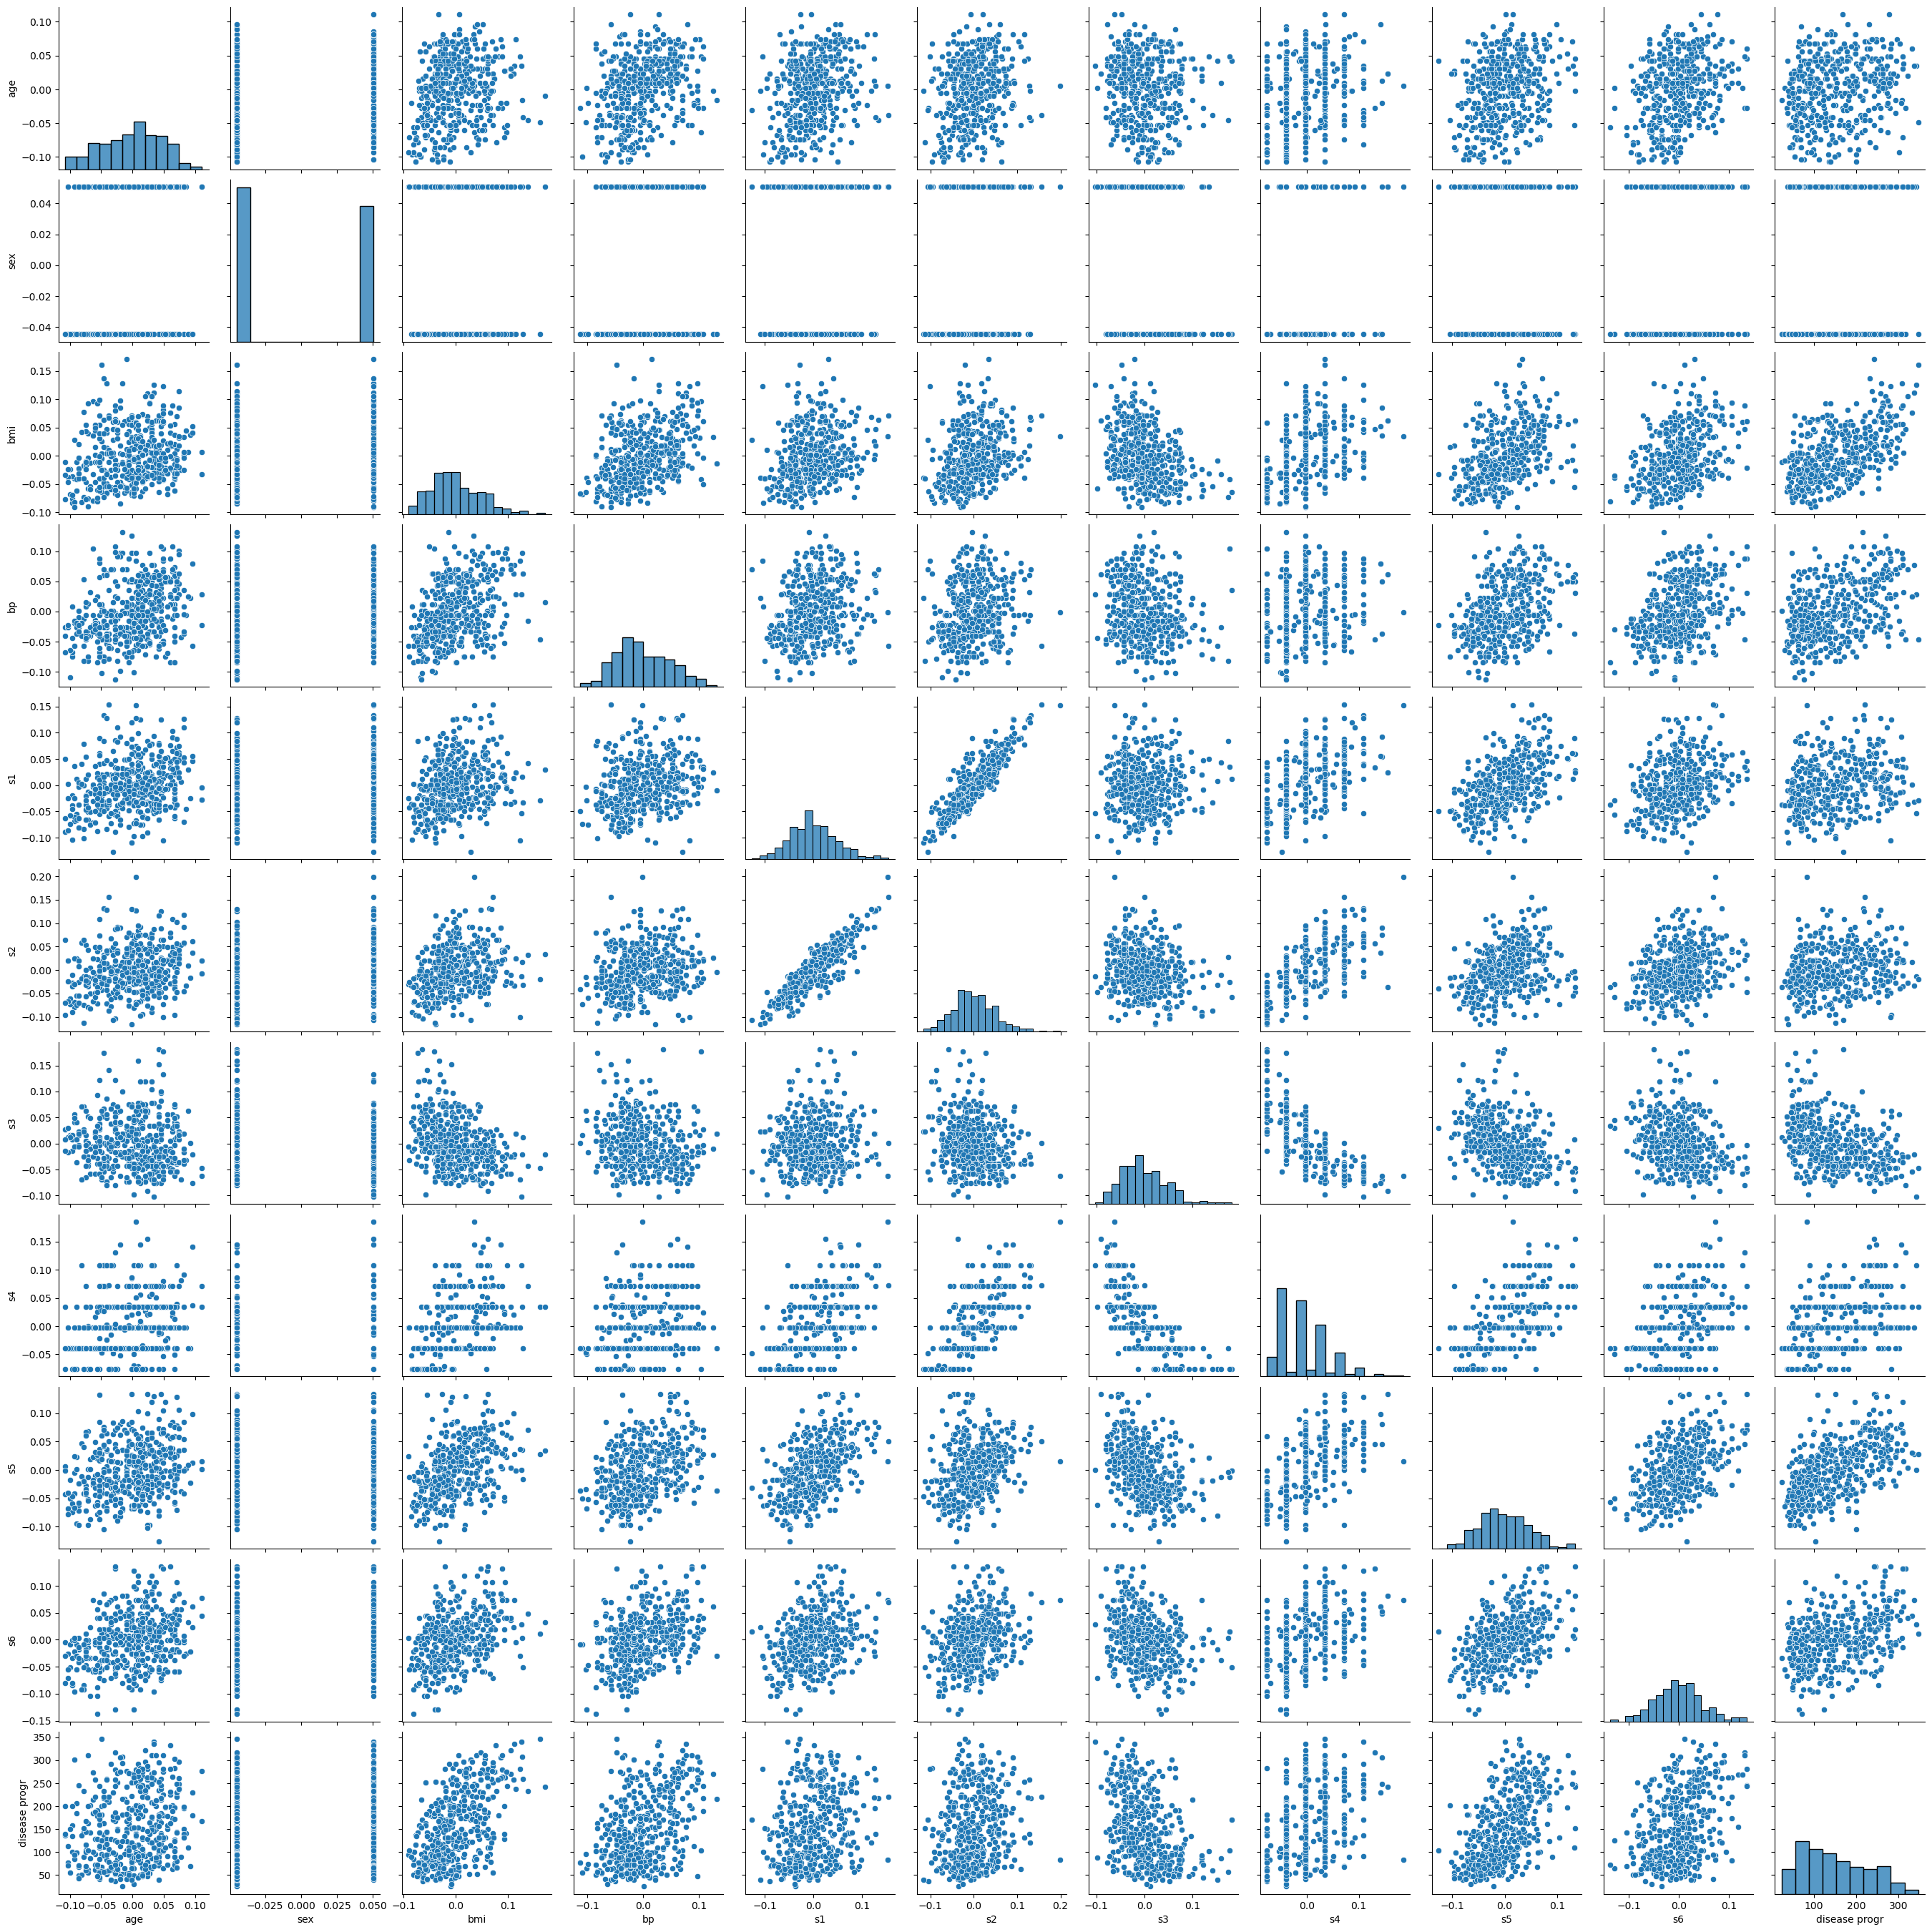

In [26]:
sns.pairplot(df_diabetes);

In [42]:
df_diabetes.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,disease progr
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


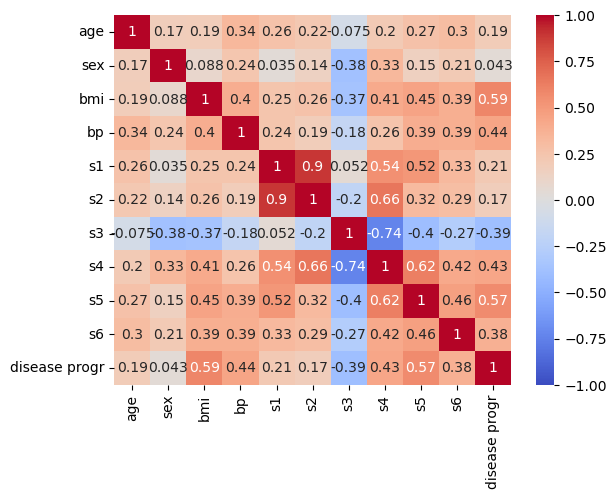

In [50]:
sns.heatmap(df_diabetes.corr(numeric_only=True), annot=True, vmin=-1, vmax=1, cmap='coolwarm');

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


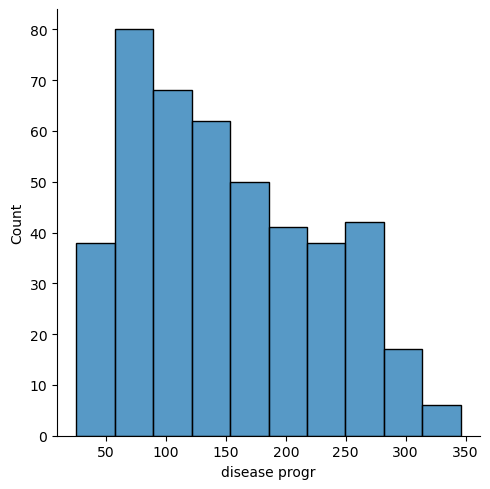

In [28]:
sns.displot(df_diabetes['disease progr']);

Fit the training data and target to `diabetes_model`. Print the *intercept* and *coefficients* of the model.

In [29]:
# diabetes_model.fit(X_train, y_train)
diabetes_model.fit(diabetes_data_train, diabetes_target_train)

LinearRegression()

In [30]:
print(diabetes_model.intercept_)
print(diabetes_model.coef_)

152.76429169049118
[ 3.06094248e-01 -2.37635570e+02  5.10538048e+02  3.27729878e+02
 -8.14111926e+02  4.92799595e+02  1.02841240e+02  1.84603496e+02
  7.43509388e+02  7.60966464e+01]


#### Inspecting the results

From the outputs you should have seen:

- The intercept is a float number.
- The coefficients are an array containing 10 float numbers.

This is the linear regression model fitted to your training dataset.

#### Using your fitted linear regression model, predict the *y* of `diabetes_data_test`.

In [31]:
# y_pred = diabetes_model.predict(X_test)
y_pred = diabetes_model.predict(diabetes_data_test)
y_pred

array([197.61898486, 155.44031962, 172.88875144, 111.53270645,
       164.79397301, 131.06765869, 259.12441219, 100.47873746,
       117.06005372, 124.30261597, 218.36868146,  61.19581944,
       132.24837933, 120.33293546,  52.54513009, 194.03746764,
       102.5756431 , 123.56778709, 211.03465323,  52.60221696])

#### Print your `diabetes_target_test` and compare with the prediction. 

In [32]:
# print(y_test)
print(diabetes_target_test)

[233.  91. 111. 152. 120.  67. 310.  94. 183.  66. 173.  72.  49.  64.
  48. 178. 104. 132. 220.  57.]


In [43]:
diabetes_target_error = y_pred - diabetes_target_test
diabetes_target_error

array([-35.38101514,  64.44031962,  61.88875144, -40.46729355,
        44.79397301,  64.06765869, -50.87558781,   6.47873746,
       -65.93994628,  58.30261597,  45.36868146, -10.80418056,
        83.24837933,  56.33293546,   4.54513009,  16.03746764,
        -1.4243569 ,  -8.43221291,  -8.96534677,  -4.39778304])

#### Is `diabetes_target_test` exactly the same as the model prediction? Use different error metrics

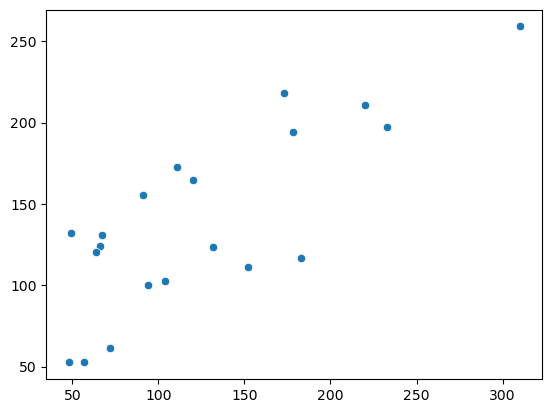

In [33]:
# sns.scatterplot(x = y_test, y = y_pred);
sns.scatterplot(x = diabetes_target_test, y = y_pred);

In [34]:
from sklearn import metrics

In [35]:
# diabetes_model.score(X_test, y_test)
diabetes_model.score(diabetes_data_test, diabetes_target_test)

0.585085427447195

In [36]:
import numpy as np

In [44]:
print('R2:', diabetes_model.score(diabetes_data_test, diabetes_target_test))
print('MAE:', metrics.mean_absolute_error(diabetes_target_test, y_pred))
print('MSE:', metrics.mean_squared_error(diabetes_target_test, y_pred))
print('RMSE:', np.sqrt(metrics.mean_squared_error(diabetes_target_test, y_pred)))
print('MAPE:', metrics.mean_absolute_percentage_error(y_true=diabetes_target_test, y_pred=y_pred))

R2: 0.585085427447195
MAE: 36.60961865545878
MSE: 2004.5186863342092
RMSE: 44.77185149548999
MAPE: 0.3930876102873052


In [45]:
y_pred_train = diabetes_model.predict(diabetes_data_train)

In [46]:
print('R2:', diabetes_model.score(diabetes_data_train, diabetes_target_train))
print('MAE:', metrics.mean_absolute_error(diabetes_target_train, y_pred_train))
print('MSE:', metrics.mean_squared_error(diabetes_target_train, y_pred_train))
print('RMSE:', np.sqrt(metrics.mean_squared_error(diabetes_target_train, y_pred_train)))
print('MAPE:', metrics.mean_absolute_percentage_error(y_true=diabetes_target_train, y_pred=y_pred_train))

R2: 0.5122247821066495
MAE: 43.61874785130125
MSE: 2901.5661704028876
RMSE: 53.86618763568559
MAPE: 0.3898167395159178


#### Iterate with a new model to assess if any improvements can be made compared to the previous one. Consider reducing the number of variables or using `StandardScaler` to enhance model performance.

In [38]:
df_diabetes.columns

Index(['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6',
       'disease progr'],
      dtype='object')

R2: 0.6129983219594721
MAE: 35.43441681464386
MSE: 1869.667026882277
RMSE: 43.23964647036649
MAPE: 0.3913135382745244


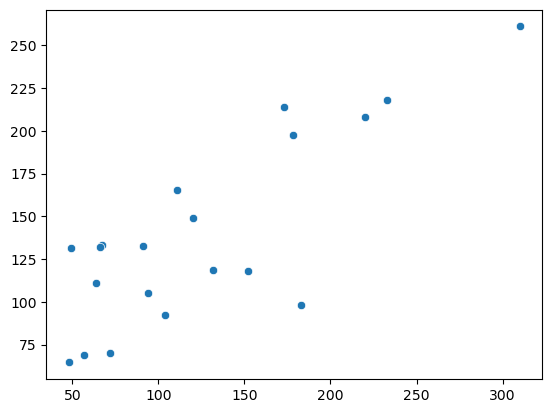

In [49]:
# Sin cross-validation 
# cols1 = ['bmi', 's5']
# cols1 = ['bmi', 'bp', 's5']
cols1 = ['sex', 'bmi', 'bp', 's1', 's5']
# X1 = df_diabetes[cols1]
# X_train1 = X_train[cols1]
# X_test1 = X_test[cols1]
# X_train1, X_test1, y_train1, y_test1 = train_test_split(df_diabetes[cols1], diabetes['target'], test_size = 0.20, random_state = 42)
X_train1 = df_diabetes[cols1][:-20]
X_test1 = df_diabetes[cols1][-20:]
y_train1 = diabetes_target_train
y_test1 = diabetes_target_test
diabetes_model1 = linear_model.LinearRegression()
diabetes_model1.fit(X_train1, y_train1)
y_pred1 = diabetes_model1.predict(X_test1)
sns.scatterplot(x = y_test1, y = y_pred1);
print('R2:', diabetes_model1.score(X_test1, y_test1))
print('MAE:', metrics.mean_absolute_error(y_test1, y_pred1))
print('MSE:', metrics.mean_squared_error(y_test1, y_pred1))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test1, y_pred1)))
print('MAPE:', metrics.mean_absolute_percentage_error(y_true=y_test1, y_pred=y_pred1))